# Target-State Selection

This notebook implements the revised target-state analysis organized along a concentrated-to-distributed target axis. The key change is that concentrated landmarks are now selected by anatomical convention, single-parcel targets are treated as exhaustive baseline distributions, and distributed targets test whether broader Gramian eigenspace support favors cycle-participation drivers.

Primary comparison: static `cycle_participation` driver sets versus static `degree_strength` driver sets at `k in {1, 2, 3, 5}`. The primary analysis writes the full subject x scale x k x target energy matrix, plus paired raw and percent-normalized differences.


In [13]:
from pathlib import Path
import os
import runpy
import sys

import pandas as pd
from IPython.display import SVG, display

os.environ.setdefault('MPLCONFIGDIR', '/private/tmp/matplotlib')

REPO_ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

RESULTS_DIR = REPO_ROOT / 'results'
STATISTICS_DIR = RESULTS_DIR / 'statistics'
FIGURES_DIR = REPO_ROOT / 'figures' / 'section_target_state_selection'
SCRIPT_PATH = REPO_ROOT / 'scripts' / '06_make_target_state_selection_figures.py'
TARGET_MAP_SCRIPT_PATH = REPO_ROOT / 'scripts' / '06_make_target_region_maps.py'


## Required Primary Outputs

Run the primary analysis before this notebook if any of these files are missing:

`python scripts/01_run_primary_analysis.py`


In [14]:
required = [
    RESULTS_DIR / 'primary' / 'target_energies.csv',
    RESULTS_DIR / 'primary' / 'target_geometry.csv',
    RESULTS_DIR / 'primary' / 'target_metadata.csv',
    STATISTICS_DIR / 'target_pairwise_differences.csv',
    STATISTICS_DIR / 'target_subject_differences.csv',
    STATISTICS_DIR / 'target_named_summary.csv',
    STATISTICS_DIR / 'target_single_parcel_tests.csv',
    STATISTICS_DIR / 'target_single_parcel_distribution_summary.csv',
]
missing = [path for path in required if not path.exists()]
if missing:
    raise FileNotFoundError('Missing target-state outputs:' + ''.join(str(path) for path in missing))
required


[PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/results/primary/target_energies.csv'),
 PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/results/primary/target_geometry.csv'),
 PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/results/primary/target_metadata.csv'),
 PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/results/statistics/target_pairwise_differences.csv'),
 PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/results/statistics/target_subject_differences.csv'),
 PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/results/statistics/target_named_summary.csv'),
 PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/results/statistics/target_single_parcel_tests.csv'),
 PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/results/statistics/target_single_parcel_distribution_summary.csv')]

## Landmark Verification

Landmarks are bilateral anatomical targets. At finer scales, all Cammoun subparcels sharing the same `base_region` are aggregated into one target, preserving the same anatomical meaning across scales.


In [15]:
metadata = pd.read_csv(RESULTS_DIR / 'primary' / 'target_metadata.csv')
landmarks = metadata[metadata['target_family'].eq('landmark')].copy()
landmarks[['scale', 'target_name', 'target_label', 'n_support_nodes', 'region_label']]


,scale,target_name,target_label,n_support_nodes,region_label
0,68,landmark_v1,V1 / pericalcarine,2,L_pericalcarine;R_pericalcarine
1,68,landmark_m1,M1 / precentral,2,L_precentral;R_precentral
2,68,landmark_pcc_precuneus,Posterior cingulate / precuneus,4,L_posteriorcingulate;L_precuneus;R_posteriorci...
3,68,landmark_lpfc,Lateral prefrontal cortex,4,L_rostralmiddlefrontal;L_caudalmiddlefrontal;R...
78,114,landmark_v1,V1 / pericalcarine,2,L_pericalcarine_1;R_pericalcarine_1
79,114,landmark_m1,M1 / precentral,7,L_precentral_1;L_precentral_2;L_precentral_3;L...
80,114,landmark_pcc_precuneus,Posterior cingulate / precuneus,6,L_posteriorcingulate_1;L_precuneus_1;L_precune...
81,114,landmark_lpfc,Lateral prefrontal cortex,7,L_rostralmiddlefrontal_1;L_rostralmiddlefronta...
202,219,landmark_v1,V1 / pericalcarine,3,L_pericalcarine_1;R_pericalcarine_1;R_pericalc...
203,219,landmark_m1,M1 / precentral,14,L_precentral_1;L_precentral_2;L_precentral_3;L...


## Full Energy Matrix

`target_energies.csv` is the non-averaged matrix used for replotting per-k results without rerunning minimum-energy calculations.


In [16]:
energies = pd.read_csv(RESULTS_DIR / 'primary' / 'target_energies.csv')
print(energies.shape)
energies.head()


(241360, 7)


,subject_id,scale,k,method,selection_strategy,target_name,target_energy
0,sub-000,68,1,degree_strength,static,landmark_v1,96635.142933
1,sub-000,68,1,degree_strength,static,landmark_m1,55597.210245
2,sub-000,68,1,degree_strength,static,landmark_pcc_precuneus,53321.483687
3,sub-000,68,1,degree_strength,static,landmark_lpfc,68893.131827
4,sub-000,68,1,degree_strength,static,single_cortical_node_000,99134.629976


## Paired Differences

The analysis stores both raw energy differences and percent-normalized differences:

- `cycle_minus_degree = E_cycle - E_degree`
- `pct_cycle_minus_degree = 100 * (E_cycle - E_degree) / E_degree`


In [17]:
pairwise = pd.read_csv(STATISTICS_DIR / 'target_pairwise_differences.csv')
subject_differences = pd.read_csv(STATISTICS_DIR / 'target_subject_differences.csv')
named_summary = pd.read_csv(STATISTICS_DIR / 'target_named_summary.csv')
parcel_summary = pd.read_csv(STATISTICS_DIR / 'target_single_parcel_distribution_summary.csv')

print('Pairwise rows:', len(pairwise))
print('Subject-averaged rows:', len(subject_differences))
named_summary.head()


Pairwise rows: 120680
Subject-averaged rows: 30170


,scale,selection_strategy,target_name,target_label,target_family,target_axis_class,axis_position,metric,n_subjects,median,ci_low,ci_high,wilcoxon_statistic,p_value,p_value_holm,reject_holm
0,68,static,association_module,Association module,module,Intermediate module,3,cycle_minus_degree,70,3338.431111,2141.422651,4407.510549,365.0,2.817089e-07,0.000003,True
1,68,static,association_vs_occipital,Association vs occipital,module,Intermediate contrast,3,cycle_minus_degree,70,1353.195917,738.964537,2536.161117,683.0,1.059255e-03,0.007415,True
2,68,static,bipolar_gradient,Bipolar gradient,distributed,Distributed,4,cycle_minus_degree,70,-1250.827829,-3480.319636,2745.629242,1212.0,8.583369e-01,1.000000,False
3,68,static,landmark_lpfc,Lateral prefrontal cortex,landmark,Concentrated landmark,1,cycle_minus_degree,70,3757.845198,2091.513003,7634.576028,759.0,4.661639e-03,0.018647,True
4,68,static,landmark_m1,M1 / precentral,landmark,Concentrated landmark,1,cycle_minus_degree,70,1240.900034,-6576.706139,8213.098591,1116.0,4.591173e-01,1.000000,False


## Named-Target Tests

Landmark, module, contrast, gradient, and uniform targets are summarized across subjects with bootstrap CIs and two-sided Wilcoxon signed-rank tests. Holm correction is applied within each scale and metric family.


In [18]:
summary_cols = [
    'scale', 'selection_strategy', 'target_name', 'target_label', 'metric',
    'n_subjects', 'median', 'ci_low', 'ci_high', 'p_value_holm', 'reject_holm',
]
named_summary[named_summary['metric'].eq('pct_cycle_minus_degree')][summary_cols]


,scale,selection_strategy,target_name,target_label,metric,n_subjects,median,ci_low,ci_high,p_value_holm,reject_holm
30,68,static,association_module,Association module,pct_cycle_minus_degree,70,8.791945,6.408580,11.775140,1.026079e-07,True
31,68,static,association_vs_occipital,Association vs occipital,pct_cycle_minus_degree,70,2.461946,1.111434,4.828896,5.727992e-03,True
32,68,static,bipolar_gradient,Bipolar gradient,pct_cycle_minus_degree,70,-1.348103,-5.017785,5.314804,1.000000e+00,False
33,68,static,landmark_lpfc,Lateral prefrontal cortex,pct_cycle_minus_degree,70,8.485846,3.148530,11.988972,5.727992e-03,True
34,68,static,landmark_m1,M1 / precentral,pct_cycle_minus_degree,70,2.480553,-13.425690,17.392361,1.000000e+00,False
35,68,static,landmark_pcc_precuneus,Posterior cingulate / precuneus,pct_cycle_minus_degree,70,17.766084,4.679851,27.895734,2.528554e-03,True
36,68,static,landmark_v1,V1 / pericalcarine,pct_cycle_minus_degree,70,-3.026482,-5.700215,-1.679311,4.154084e-04,True
37,68,static,occipital_module,Occipital module,pct_cycle_minus_degree,70,-10.036333,-13.108116,-3.678474,2.828467e-05,True
38,68,static,principal_gradient,Principal gradient,pct_cycle_minus_degree,70,-6.782644,-9.752058,-1.110117,1.168769e-02,True
39,68,static,uniform_cortical,Uniform cortical,pct_cycle_minus_degree,70,4.330063,0.118649,7.997316,3.524261e-01,False


## Exhaustive Single-Parcel Baseline

Cortical and subcortical single-parcel targets are summarized as separate distributions. The Cammoun outputs here are cortical-only, so the subcortical table is expected to be empty unless a later atlas adds those parcels.


In [19]:
parcel_summary[parcel_summary['metric'].eq('pct_cycle_minus_degree')]


,scale,selection_strategy,target_family,metric,n_parcels,median_parcel_subject_average,ci_low,ci_high,n_significantly_negative,n_significantly_positive,n_null,fraction_significantly_negative,fraction_significantly_positive,fraction_null
3,68,static,single_cortical_parcel,pct_cycle_minus_degree,68,-0.296080,-1.368158,13.375845,26,16,26,0.382353,0.235294,0.382353
4,114,static,single_cortical_parcel,pct_cycle_minus_degree,114,-0.899387,-1.586561,-0.537608,57,29,28,0.500000,0.254386,0.245614
5,219,static,single_cortical_parcel,pct_cycle_minus_degree,219,-0.426652,-0.604328,-0.269964,110,50,59,0.502283,0.228311,0.269406


## Replacement Figure

The replacement figure is organized top-to-bottom along the concentrated-to-distributed axis:

1. Exhaustive cortical single-parcel baseline distributions with V1, M1, PCC/precuneus, and lPFC landmarks overlaid.
2. Association module, occipital module, and association-vs-occipital contrast.
3. Principal gradient, bipolar gradient, and uniform cortical activation.


/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_target_state_selection/target_state_spectral_axis_static_pct.svg
/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_target_state_selection/target_state_spectral_axis_static_raw.svg


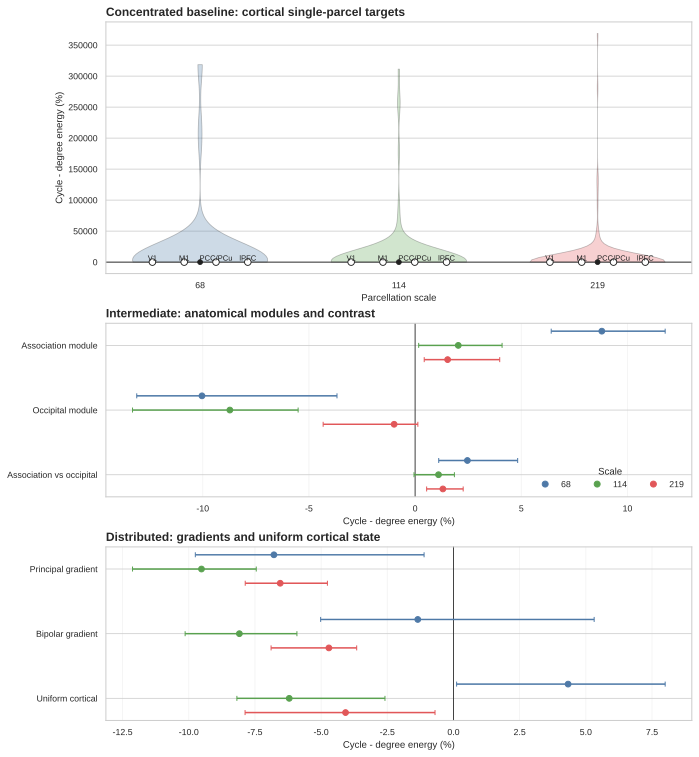

PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_target_state_selection/target_state_spectral_axis_static_pct.svg')

In [20]:
runpy.run_path(str(SCRIPT_PATH), run_name='__main__')
primary_figure = FIGURES_DIR / 'target_state_spectral_axis_static_pct.svg'
display(SVG(filename=str(primary_figure)))
primary_figure


## Target Region Map Exports

These exports draw the named target states only: landmarks, module/contrast targets, gradients, and uniform cortical activation. The exhaustive single-parcel baseline is intentionally skipped. Change `TARGET_MAP_SCALE` to `68`, `114`, `219`, or `'all'` before running the cell.

Each SVG contains an embedded rasterized brain image to keep file sizes reasonable while retaining an editable SVG container.


In [21]:
import subprocess

TARGET_MAP_SCALE = 219  # 68, 114, 219, or 'all'
cmd = [sys.executable, str(TARGET_MAP_SCRIPT_PATH), '--scale', str(TARGET_MAP_SCALE)]
completed = subprocess.run(cmd, cwd=REPO_ROOT, check=True, capture_output=True, text=True)
exported_target_maps = [Path(line) for line in completed.stdout.splitlines() if line.strip()]
print(f'Exported {len(exported_target_maps)} target maps at scale {TARGET_MAP_SCALE}')
exported_target_maps[:5]


Exported 10 target maps at scale 219


[PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_target_state_selection/target_region_maps_scale-219/target_landmark_v1_scale-219.svg'),
 PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_target_state_selection/target_region_maps_scale-219/target_landmark_m1_scale-219.svg'),
 PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_target_state_selection/target_region_maps_scale-219/target_landmark_pcc_precuneus_scale-219.svg'),
 PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_target_state_selection/target_region_maps_scale-219/target_landmark_lpfc_scale-219.svg'),
 PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_target_state_selection/target_region_maps_scale-219/target_association_module_scale-219.svg')]

## Spectral Spread Diagnostics

`target_geometry.csv` includes effective-mode spread metrics for each target in the Gramian eigenbasis, allowing the concentrated-to-distributed ordering to be checked directly against eigenspace support.


In [22]:
geometry = pd.read_csv(RESULTS_DIR / 'primary' / 'target_geometry.csv')
spread = (
    geometry[geometry['selection_strategy'].eq('static')]
    .merge(metadata[['scale', 'target_name', 'target_label', 'target_family']], on=['scale', 'target_name'], how='left')
    .groupby(['scale', 'target_name', 'target_label', 'target_family'], as_index=False)
    .agg(
        median_spectral_spread=('spectral_spread_effective_modes', 'median'),
        median_entropy_spread=('spectral_entropy_effective_modes', 'median'),
    )
)
spread.sort_values(['target_family', 'scale', 'median_spectral_spread']).head(20)


,scale,target_name,target_label,target_family,median_spectral_spread,median_entropy_spread
77,68,uniform_cortical,Uniform cortical,distributed,10.963047,20.237776
8,68,principal_gradient,Principal gradient,distributed,15.651351,24.904578
2,68,bipolar_gradient,Bipolar gradient,distributed,17.921854,27.286395
201,114,uniform_cortical,Uniform cortical,distributed,14.975927,29.590179
86,114,principal_gradient,Principal gradient,distributed,23.563409,39.942802
80,114,bipolar_gradient,Bipolar gradient,distributed,24.333249,40.877874
430,219,uniform_cortical,Uniform cortical,distributed,24.962933,56.539730
204,219,bipolar_gradient,Bipolar gradient,distributed,43.505269,79.410090
210,219,principal_gradient,Principal gradient,distributed,46.422459,82.598162
5,68,landmark_pcc_precuneus,Posterior cingulate / precuneus,landmark,9.206982,17.181880
